# 36개 피처 기반 재모델링 — 다중 모델 튜닝과 앙상블
**원본 26개 + 파생변수 10개(형상·밝기·위치·강판 맥락) = 36개 피처를 고정하고, 모델을 처음부터 다시 튜닝한 뒤 앙상블(Soft Voting·Stacking)로 성능이 오르는지 확인합니다.**

| 항목 | 설정 |
|---|---|
| 입력 | `add_features()` 행 단위 파생변수 8개 + `PlateContextEncoder`(Training fold에서만 계산) 2개 → 36개 |
| 후보 모델 | LightGBM, XGBoost, ExtraTrees(신규), Random Forest, GBM — 각 모델을 **새로 RandomizedSearchCV** (샘플러·클래스 가중치도 탐색) |
| 앙상블 | 튜닝 모델들의 OOF 확률로 **Soft Voting**(조합별 균등 평균), **Stacking**(로지스틱 회귀 메타 모델) |
| 검증 | 팀 공통 `StratifiedKFold(5, shuffle=True, random_state=42)` → 상위 후보는 반복 층화 CV(5×3) |
| 비교 기준 | 현재 최종 모델(파생변수 36개 + 재튜닝 LightGBM): 5-fold 0.8317, 반복 CV 0.8295, Test 0.823 |
| Test | 최종 후보 1개만 1회 평가 (Test는 이미 이전 후보 평가에 2회 사용되었으므로 결과 해석 시 유의) |

> **실행 시간**: 처음 실행 시 2코어 기준 약 약 25분. 결과는 `results/modeling_v2/Taegyeom_v2_cache.pkl`에 저장되어 `RERUN = False`(기본값)면 수 초 안에 끝납니다.

In [1]:
import sys, warnings, pickle, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from itertools import combinations

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore")

from config import RANDOM_STATE, CV
from load_data import load_data
from Taegyeom_model_utils import (CLASS_ORDER, build_preprocessor, discrete_indices, over_strategy, LabelEncodedClassifier,
                                  BalancedWeightClassifier, per_class_report, confusion_df, key_error_counts,
                                  add_features, PlateContextEncoder)
from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import Parallel, delayed

RESULT_DIR = PROJECT_ROOT / "results" / "modeling_v2"; RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)

RERUN = False
CACHE = RESULT_DIR / "Taegyeom_v2_cache.pkl"
cache = pickle.load(open(CACHE, "rb")) if (CACHE.exists() and not RERUN) else {}
def cached(key, fn):
    if key not in cache:
        cache[key] = fn(); pickle.dump(cache, open(CACHE, "wb"))
    return cache[key]

BLUE, BLUE_LIGHT, ORANGE, AQUA, RED = "#2a78d6", "#86b6ef", "#eb6834", "#1baf7a", "#e34948"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams.update({
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
})
def save(fig, name): fig.savefig(FIG_DIR / name); plt.show()

## 1. 데이터 — 36개 피처

In [2]:
X_train, X_test, y_train, y_test = load_data()
RS = RANDOM_STATE
XF_train, XF_test = add_features(X_train), add_features(X_test)                    # 34개 (행 단위)
FE_FEATURES = list(XF_train.columns) + ["plate_defect_count", "thickness_per_conveyer"]  # 파이프라인 안에서 36개
CAT = discrete_indices(FE_FEATURES)
print("행 단위 입력:", XF_train.shape, "→ 모델 입력 피처 수:", len(FE_FEATURES))
smotenc = lambda: SMOTENC(categorical_features=CAT, sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RS)

def fe_pipe(model, scale=False, sampler=None):
    return ImbPipeline([("plate", PlateContextEncoder()), ("prep", build_preprocessor(FE_FEATURES, scale=scale)),
                        ("sampler", sampler if sampler is not None else "passthrough"), ("model", model)])

행 단위 입력: (1552, 34) → 모델 입력 피처 수: 36


## 2. 모델별 하이퍼파라미터 탐색 (36개 피처, 처음부터)
- 각 모델의 탐색 공간에 **샘플러(SMOTENC 균등화 / 없음)** 와 **클래스 가중치**를 함께 넣어 불균형 처리 방식도 다시 고릅니다.
- ExtraTrees는 분할 기준을 무작위로 정하는 트리 앙상블로, Boosting 모델과 오류 패턴이 달라 앙상블 다양성을 위해 새로 추가했습니다.

In [3]:
XP, GP = "model__estimator__estimator__", "model__estimator__"
SEARCH = {
    "LightGBM": dict(n_iter=25, pipe=fe_pipe(LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1, subsample_freq=1), sampler=smotenc()),
        space={"sampler": [smotenc(), "passthrough"], "model__class_weight": [None, "balanced"],
               "model__n_estimators": randint(200, 900), "model__learning_rate": loguniform(0.01, 0.15),
               "model__num_leaves": randint(8, 64), "model__max_depth": [-1, 4, 6, 8, 10], "model__min_child_samples": randint(5, 40),
               "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.3, 0.7), "model__reg_lambda": loguniform(1e-3, 10)}),
    "XGBoost": dict(n_iter=25, pipe=fe_pipe(BalancedWeightClassifier(LabelEncodedClassifier(XGBClassifier(random_state=RS, n_jobs=1)), alpha=0), sampler=smotenc()),
        space={"sampler": [smotenc(), "passthrough"], "model__alpha": [0, 0.5, 1],
               XP + "n_estimators": randint(150, 900), XP + "learning_rate": loguniform(0.01, 0.15), XP + "max_depth": randint(3, 9),
               XP + "min_child_weight": randint(1, 8), XP + "subsample": uniform(0.6, 0.4), XP + "colsample_bytree": uniform(0.3, 0.7),
               XP + "reg_lambda": loguniform(1e-2, 10), XP + "gamma": loguniform(1e-3, 1)}),
    "ExtraTrees": dict(n_iter=15, pipe=fe_pipe(ExtraTreesClassifier(random_state=RS, n_jobs=1), sampler=smotenc()),
        space={"sampler": [smotenc(), "passthrough"], "model__class_weight": [None, "balanced", "balanced_subsample"],
               "model__n_estimators": randint(300, 900), "model__max_depth": [None, 15, 25], "model__min_samples_leaf": randint(1, 5),
               "model__max_features": ["sqrt", 0.3, 0.5, 0.7]}),
    "Random Forest": dict(n_iter=12, pipe=fe_pipe(RandomForestClassifier(random_state=RS, n_jobs=1), sampler=smotenc()),
        space={"sampler": [smotenc(), "passthrough"], "model__class_weight": [None, "balanced_subsample"],
               "model__n_estimators": randint(300, 700), "model__max_depth": [None, 15, 25], "model__min_samples_leaf": randint(1, 5),
               "model__max_features": ["sqrt", 0.3, 0.5]}),
    "GBM": dict(n_iter=8, pipe=fe_pipe(BalancedWeightClassifier(GradientBoostingClassifier(random_state=RS), alpha=1)),
        space={"model__alpha": [0.5, 1], GP + "n_estimators": randint(100, 350), GP + "learning_rate": loguniform(0.03, 0.2),
               GP + "max_depth": randint(3, 6), GP + "subsample": uniform(0.6, 0.4), GP + "max_features": [None, "sqrt", 0.5],
               GP + "min_samples_leaf": randint(1, 10)}),
}
def do_search(name):
    s = SEARCH[name]
    rs = RandomizedSearchCV(s["pipe"], s["space"], n_iter=s["n_iter"], scoring="f1_macro", cv=CV, n_jobs=-1,
                            random_state=RS + 7, return_train_score=True, refit=False)   # 이전 탐색과 다른 난수열
    t0 = time.perf_counter(); rs.fit(XF_train, y_train)
    r = pd.DataFrame(rs.cv_results_); r["search_sec"] = time.perf_counter() - t0; return r

t_all = time.perf_counter(); searches, best_params = {}, {}
for name in SEARCH:
    r = cached(("search", name), lambda n=name: do_search(n)); searches[name] = r
    b = r.loc[r["rank_test_score"].idxmin()]; best_params[name] = b["params"]
    samp = "-" if "param_sampler" not in r else ("SMOTENC" if not isinstance(b["params"].get("sampler", "passthrough"), str) else "없음")
    print(f"{name:14s} 최고 CV Macro F1 {b['mean_test_score']:.4f} ± {b['std_test_score']:.4f} | Train {b['mean_train_score']:.3f} | 샘플러 {samp} | {r['search_sec'].iloc[0]:.0f}초")
print(f"소요 {time.perf_counter() - t_all:.0f}초")

LightGBM       최고 CV Macro F1 0.8329 ± 0.0160 | Train 1.000 | 샘플러 SMOTENC | 295초
XGBoost        최고 CV Macro F1 0.8320 ± 0.0156 | Train 1.000 | 샘플러 SMOTENC | 291초
ExtraTrees     최고 CV Macro F1 0.8180 ± 0.0185 | Train 1.000 | 샘플러 없음 | 122초
Random Forest  최고 CV Macro F1 0.8125 ± 0.0218 | Train 1.000 | 샘플러 없음 | 244초
GBM            최고 CV Macro F1 0.8382 ± 0.0145 | Train 1.000 | 샘플러 - | 226초
소요 0초


## 3. 튜닝 모델의 OOF 예측 확률 (같은 5-fold)
최적 설정으로 fold마다 다시 학습해 **out-of-fold 확률**을 얻습니다. 앙상블은 이 확률을 조합해 평가하므로, 모델을 다시 학습하지 않고도 많은 조합을 공정하게(같은 fold) 비교할 수 있습니다.

In [4]:
def tuned(name):
    return clone(SEARCH[name]["pipe"]).set_params(**best_params[name])
splits = list(CV.split(XF_train, y_train))

def fold_proba(name, k, tr, va):
    m = tuned(name); m.fit(XF_train.iloc[tr], y_train.iloc[tr])
    p = pd.DataFrame(m.predict_proba(XF_train.iloc[va]), columns=m.classes_)[CLASS_ORDER].values
    ptr = f1_score(y_train.iloc[tr], m.predict(XF_train.iloc[tr]), average="macro")
    return name, k, p, ptr

def all_oof():
    outs = Parallel(n_jobs=-1)(delayed(fold_proba)(n, k, tr, va) for n in SEARCH for k, (tr, va) in enumerate(splits))
    oof = {n: np.zeros((len(y_train), 7)) for n in SEARCH}; trs = {n: [] for n in SEARCH}
    for n, k, p, ptr in outs:
        oof[n][splits[k][1]] = p; trs[n].append(ptr)
    return oof, trs

t0 = time.perf_counter(); OOF, TRAIN_F1 = cached("oof", all_oof); print(f"소요 {time.perf_counter() - t0:.0f}초")
CLS = np.array(CLASS_ORDER); yv = y_train.values

def fold_scores(P):
    pred = CLS[P.argmax(1)]
    return np.array([f1_score(yv[va], pred[va], average="macro") for _, va in splits])

single = pd.DataFrame({n: {"5-fold Macro F1": fold_scores(OOF[n]).mean(), "std": fold_scores(OOF[n]).std(),
                           "OOF Macro F1": f1_score(yv, CLS[OOF[n].argmax(1)], average="macro"),
                           "Train Macro F1": np.mean(TRAIN_F1[n])} for n in SEARCH}).T.sort_values("5-fold Macro F1", ascending=False)
single.round(4)

소요 0초


,5-fold Macro F1,std,OOF Macro F1,Train Macro F1
GBM,0.8382,0.0145,0.8392,1.0
LightGBM,0.8329,0.0160,0.8340,1.0
XGBoost,0.8320,0.0156,0.8333,1.0
ExtraTrees,0.8180,0.0185,0.8199,1.0
Random Forest,0.8109,0.0202,0.8115,1.0


## 4. 앙상블
### 4-1. Soft Voting — 모델 조합별 확률 평균
2~5개 모델의 모든 조합(26가지)을 같은 fold에서 비교합니다. 가중치는 균등으로 두어(가중치를 OOF로 최적화하면 낙관적) 과적합을 피합니다.

In [5]:
names = list(SEARCH)
vote_rows = []
for r in range(2, len(names) + 1):
    for combo in combinations(names, r):
        P = np.mean([OOF[n] for n in combo], axis=0); fs = fold_scores(P)
        vote_rows.append({"조합": " + ".join(combo), "모델 수": r, "5-fold Macro F1": fs.mean(), "std": fs.std(),
                          "최고 단일 모델 대비": fs.mean() - max(fold_scores(OOF[n]).mean() for n in combo)})
votes = pd.DataFrame(vote_rows).sort_values("5-fold Macro F1", ascending=False).reset_index(drop=True)
votes.to_csv(RESULT_DIR / "Taegyeom_v2_soft_voting_combos.csv", index=False)
votes.head(10).round(4)

,조합,모델 수,5-fold Macro F1,std,최고 단일 모델 대비
0,ExtraTrees + Random Forest + GBM,3,0.8430,0.0211,0.0048
1,ExtraTrees + GBM,2,0.8421,0.0160,0.0039
2,XGBoost + ExtraTrees + Random Forest + GBM,4,0.8396,0.0134,0.0014
3,LightGBM + ExtraTrees + GBM,3,0.8396,0.0141,0.0013
4,LightGBM + ExtraTrees + Random Forest + GBM,4,0.8393,0.0146,0.0010
5,XGBoost + Random Forest + GBM,3,0.8388,0.0150,0.0006
6,LightGBM + Random Forest + GBM,3,0.8385,0.0116,0.0003
7,XGBoost + ExtraTrees + GBM,3,0.8385,0.0148,0.0002
8,LightGBM + XGBoost + Random Forest + GBM,4,0.8380,0.0143,-0.0003
9,Random Forest + GBM,2,0.8378,0.0159,-0.0005


### 4-2. Stacking — 로지스틱 회귀 메타 모델
5개 튜닝 모델의 OOF 확률(35개 값)을 입력으로 메타 모델(다항 로지스틱 회귀)이 최종 클래스를 예측합니다. 메타 모델도 **같은 5-fold로 교차 예측**하여 평가합니다
(기본 모델 OOF 확률은 메타 모델의 학습 fold와 일부 겹치는 데이터로 학습되어 약간 낙관적일 수 있음).

In [6]:
def stack_eval(model_names, C):
    Z = np.hstack([OOF[n] for n in model_names]); pred = np.empty(len(yv), dtype=object)
    for tr, va in splits:
        meta = LogisticRegression(C=C, max_iter=5000).fit(np.log(Z[tr] + 1e-6), yv[tr]); pred[va] = meta.predict(np.log(Z[va] + 1e-6))
    return np.array([f1_score(yv[va], pred[va], average="macro") for _, va in splits]), pred
stack_rows = []
for combo in [tuple(names), ("LightGBM", "XGBoost", "ExtraTrees"), ("LightGBM", "XGBoost", "GBM"), ("LightGBM", "ExtraTrees")]:
    for C in [0.03, 0.1, 0.3, 1.0]:
        fs, _ = stack_eval(combo, C)
        stack_rows.append({"기본 모델": " + ".join(combo), "C": C, "5-fold Macro F1": fs.mean(), "std": fs.std()})
stacks = pd.DataFrame(stack_rows).sort_values("5-fold Macro F1", ascending=False).reset_index(drop=True)
stacks.to_csv(RESULT_DIR / "Taegyeom_v2_stacking.csv", index=False)
stacks.head(8).round(4)

,기본 모델,C,5-fold Macro F1,std
0,LightGBM + XGBoost + GBM,0.10,0.8325,0.0144
1,LightGBM + XGBoost + GBM,0.03,0.8325,0.0137
2,LightGBM + XGBoost + ExtraTrees + Random Fores...,0.10,0.8305,0.0237
3,LightGBM + XGBoost + GBM,0.30,0.8296,0.0128
4,LightGBM + XGBoost + ExtraTrees + Random Fores...,0.03,0.8262,0.0254
5,LightGBM + XGBoost + ExtraTrees + Random Fores...,0.30,0.8260,0.0221
6,LightGBM + XGBoost + ExtraTrees,0.10,0.8257,0.0236
7,LightGBM + XGBoost + GBM,1.00,0.8256,0.0147


## 5. 후보 비교와 반복 층화 CV(5×3) 확인

In [8]:
best_vote = votes.iloc[0]["조합"].split(" + ")
best_single = single.index[0]
cands = {f"단일: {best_single}": [best_single], f"Soft Voting: {' + '.join(best_vote)}": best_vote}
print("반복 CV 확인 후보:", list(cands))
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS); rsplits = list(RCV.split(XF_train, y_train))
need = sorted({n for v in cands.values() for n in v})

def rep_fold(name, i, tr, va):
    m = tuned(name); m.fit(XF_train.iloc[tr], y_train.iloc[tr])
    return name, i, pd.DataFrame(m.predict_proba(XF_train.iloc[va]), columns=m.classes_)[CLASS_ORDER].values

def rep_all():
    outs = Parallel(n_jobs=-1)(delayed(rep_fold)(n, i, tr, va) for n in need for i, (tr, va) in enumerate(rsplits))
    return {(n, i): p for n, i, p in outs}
t0 = time.perf_counter()
REP = cached(("repeated", tuple(need)), rep_all); print(f"소요 {time.perf_counter() - t0:.0f}초")

fe_cache = pickle.load(open(PROJECT_ROOT / "results/feature_engineering/Taegyeom_fe_cache.pkl", "rb"))
cur_rep = fe_cache[("retune_repeated", "+전체 (36개)")]              # 현재 최종 모델 반복 CV (같은 분할)
rows = [{"후보": "현재 최종: LightGBM (36개, 이전 재튜닝)", "5-fold Macro F1": 0.8317, "반복 CV(5×3)": cur_rep.mean(), "반복 CV std": cur_rep.std(),
         "현재 최종보다 좋은 fold": "—"}]
rep_scores = {}
for label, members in cands.items():
    s = np.array([f1_score(y_train.iloc[va], CLS[np.mean([REP[(n, i)] for n in members], axis=0).argmax(1)], average="macro")
                  for i, (_, va) in enumerate(rsplits)])
    rep_scores[label] = s
    five = fold_scores(np.mean([OOF[n] for n in members], axis=0)).mean()
    rows.append({"후보": label, "5-fold Macro F1": five, "반복 CV(5×3)": s.mean(), "반복 CV std": s.std(),
                 "현재 최종보다 좋은 fold": f"{(s > cur_rep).sum()}/15"})
cmp_tbl = pd.DataFrame(rows).set_index("후보")
cmp_tbl.to_csv(RESULT_DIR / "Taegyeom_v2_candidate_comparison.csv")
cmp_tbl.round(4)

반복 CV 확인 후보: ['단일: GBM', 'Soft Voting: ExtraTrees + Random Forest + GBM']
소요 0초


,5-fold Macro F1,반복 CV(5×3),반복 CV std,현재 최종보다 좋은 fold
후보,,,,
"현재 최종: LightGBM (36개, 이전 재튜닝)",0.8317,0.8295,0.0180,—
단일: GBM,0.8382,0.8355,0.0181,9/15
Soft Voting: ExtraTrees + Random Forest + GBM,0.8430,0.8395,0.0236,11/15


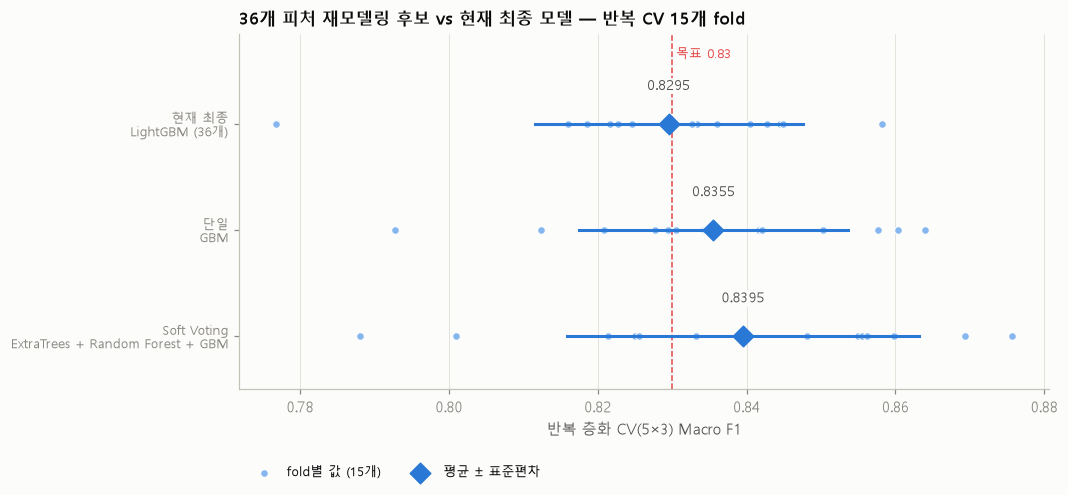

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
items = [("현재 최종\nLightGBM (36개)", cur_rep)] + [(k.replace(": ", "\n"), v) for k, v in rep_scores.items()]
for i, (lab, v) in enumerate(items):
    ax.scatter(v, [i] * len(v), s=26, color=BLUE_LIGHT, edgecolor=SURFACE, lw=0.8, zorder=2, label="fold별 값 (15개)" if i == 0 else None)
    ax.plot([v.mean() - v.std(), v.mean() + v.std()], [i, i], color=BLUE, lw=2, zorder=3)
    ax.scatter([v.mean()], [i], s=90, marker="D", color=BLUE, zorder=4, label="평균 ± 표준편차" if i == 0 else None)
    ax.text(v.mean(), i - 0.32, f"{v.mean():.4f}", ha="center", fontsize=9, color=INK2, bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.axvline(0.83, color=RED, lw=1, ls="--"); ax.text(0.8305, -0.62, "목표 0.83", color=RED, fontsize=8.5)
ax.set_yticks(range(len(items)), [l for l, _ in items], fontsize=8.5); ax.invert_yaxis(); ax.set_ylim(len(items) - 0.5, -0.85)
ax.grid(axis="y", visible=False); ax.set_xlabel("반복 층화 CV(5×3) Macro F1")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=2, frameon=False, fontsize=8.5)
ax.set_title("36개 피처 재모델링 후보 vs 현재 최종 모델 — 반복 CV 15개 fold")
save(fig, "Taegyeom_v2_repeated_cv.png")

## 6. 최종 후보 선정과 Test 1회 평가

In [10]:
# 선정 규칙(Test 보기 전에 고정): 반복 CV 평균이 현재 최종보다 높고 15 fold 중 과반(8개 이상)에서 좋으면 교체, 아니면 현재 최종 유지
best_label = max(rep_scores, key=lambda k: rep_scores[k].mean())
s = rep_scores[best_label]; better = int((s > cur_rep).sum())
switch = (s.mean() > cur_rep.mean()) and better >= 8
print(f"반복 CV 최고 후보: {best_label}  {s.mean():.4f} (현재 최종 {cur_rep.mean():.4f}, 좋은 fold {better}/15) → {'교체' if switch else '현재 최종 유지'}")

if switch:
    members = cands[best_label]
    def fit_full(n):
        m = tuned(n); m.fit(XF_train, y_train)
        return n, pd.DataFrame(m.predict_proba(XF_test), columns=m.classes_)[CLASS_ORDER].values   # 캐시 용량을 줄이려 확률만 저장
    fitted = cached(("test_fit", tuple(members)), lambda: Parallel(n_jobs=-1)(delayed(fit_full)(n) for n in members))
    P_test = np.mean([p for _, p in fitted], axis=0); pred = CLS[P_test.argmax(1)]
    rng = np.random.default_rng(RS); ytv = y_test.values
    boot = np.array([f1_score(ytv[i], pred[i], average="macro") for i in (rng.integers(0, len(ytv), len(ytv)) for _ in range(2000))])
    test_f1 = f1_score(ytv, pred, average="macro")
    res = {"후보": best_label, "Test Macro F1": round(test_f1, 4), "95% CI": [round(x, 4) for x in np.percentile(boot, [2.5, 97.5])],
           "Test Accuracy": round(accuracy_score(ytv, pred), 4), "현재 최종 Test Macro F1": 0.8226}
    json.dump(res, open(RESULT_DIR / "Taegyeom_v2_test_result.json", "w"), ensure_ascii=False, indent=2)
    pc = pd.concat({"신규 후보": per_class_report(y_test, pred)}, axis=1).round(3); pc.to_csv(RESULT_DIR / "Taegyeom_v2_test_per_class.csv")
    print(res); display(pc); display(pd.DataFrame({"신규 후보": key_error_counts(y_test, pred)}))
else:
    print("교체 기준을 넘지 못해 Test 평가를 추가로 하지 않습니다 (불필요한 Test 재사용 방지).")

반복 CV 최고 후보: Soft Voting: ExtraTrees + Random Forest + GBM  0.8395 (현재 최종 0.8295, 좋은 fold 11/15) → 교체
{'후보': 'Soft Voting: ExtraTrees + Random Forest + GBM', 'Test Macro F1': 0.8279, '95% CI': [np.float64(0.7851), np.float64(0.8647)], 'Test Accuracy': 0.8046, '현재 최종 Test Macro F1': 0.8226}


신규 후보                      
             precision recall     f1 support
Other_Faults     0.738  0.793  0.764     135
Bumps            0.734  0.716  0.725      81
K_Scratch        0.986  0.936  0.961      78
Z_Scratch        1.000  0.947  0.973      38
Pastry           0.531  0.531  0.531      32
Stains           0.923  0.857  0.889      14
Dirtiness        1.000  0.909  0.952      11

,신규 후보
소수 유형 → Other_Faults·Bumps,18
Other_Faults → 소수 유형 (오경보),11
Bumps ↔ Other_Faults,35
K_Scratch ↔ Z_Scratch,0
전체 오분류,76


## 7. 결과 해석 (성능 비교는 반복 층화 CV(5×3) 평균 기준)
> 5-fold 점수는 여러 설정·조합 중 최고값을 고른 값이라 낙관적이므로, 판단은 **다른 분할로 다시 평가한 반복 CV(5×3) 평균**으로 합니다.

**단일 모델 — 36개 피처에서는 GBM이 가장 좋음**
- 튜닝 GBM(클래스 가중치 α=1, 트리 240개, 깊이 4, 피처 50% 샘플링)의 반복 CV는 **0.8355**로, 현재 최종 LightGBM(0.8295)보다 +0.006 높습니다(15 fold 중 9개 개선).
- ExtraTrees(0.8144)와 Random Forest(0.8113)는 단독으로는 현재 최종보다 낮습니다.

**앙상블 — 서로 다른 모델의 조합이 효과적**
- **Soft Voting(ExtraTrees + Random Forest + GBM)의 반복 CV는 0.8395**로, 현재 최종 대비 **+0.010**(15 fold 중 11개 개선)이며 **목표 0.83을 반복 CV 평균에서 처음으로 넘었습니다**(0.83 이상 fold: 10/15, 현재 최종 8/15).
- 단독으로는 약한 ExtraTrees·Random Forest(배깅 계열, 샘플러 없음)가 Boosting 계열 GBM과 오류 패턴이 달라, 확률을 평균하면 서로의 실수를 보완합니다(다양성 효과).
  반대로 비슷한 Boosting 모델끼리(LightGBM + XGBoost + GBM)의 조합은 개선이 거의 없었습니다.
- **Stacking**(로지스틱 회귀 메타 모델)은 Soft Voting보다 낮아 채택하지 않았습니다. 학습 데이터가 1,552건으로 적어 메타 모델이 확률 조합 가중치를 안정적으로 배우기 어렵습니다.
- 개선의 불확실성: fold별 차이는 평균 +0.010, 표준편차 0.019로 차이/표준오차 ≈ 2 수준입니다. 이전 실험들(+0.0035 등)보다 뚜렷하지만, 반복 CV fold끼리 독립이 아니라서 통계적으로 확정적이라고 보기는 어렵습니다.

**Test 1회 평가 (선정 규칙을 Test 전에 고정: 반복 CV 평균이 높고 과반 fold에서 개선 시 교체)**
- Soft Voting Test Macro F1 **0.828** (95% CI 0.785 ~ 0.865), 현재 최종 0.823보다 +0.005. 방향은 CV와 같지만 차이는 Test 389건의 변동 범위 안입니다.
- 클래스별로는 Dirtiness F1 0.952, Z_Scratch 0.973, K_Scratch 0.961로 높고, **Pastry F1 0.531로 여전히 가장 약하며** Bumps ↔ Other_Faults 혼동은 35건입니다.
- Test는 이전 후보 평가에 이미 두 번 사용되었으므로, 이 Test 점수는 참고용이며 모델 선택 근거는 반복 CV입니다.

**결론**: 36개 피처에서 모델을 새로 튜닝하고 앙상블한 결과, **Soft Voting(ExtraTrees + Random Forest + GBM)이 반복 CV 0.8395로 가장 높아 최종 후보로 교체할 근거가 있습니다.**
학습 시간은 단일 LightGBM보다 길고(모델 3개) 해석은 다소 복잡해지는 Trade-off가 있습니다.

→ 이 근거(반복 CV 평균 최고 + 15 fold 중 11개 개선)로 **Soft Voting(ExtraTrees + Random Forest + GBM)을 최종 모델로 확정**했으며, 최종 평가는 `Taegyeom_final_evaluation.ipynb`에 정리했습니다.